In [5]:
!pip install matplotlib
import math
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

Defaulting to user installation because normal site-packages is not writeable


## Bisection

**Characteristics:** Brackets the root between a lower and upper limit where the function changes sign, then repeatedly halves the interval. Guaranteed linear convergence — always converges if the initial bracket is valid. Only needs function evaluations (no derivative).

**Limitations:** Requires an initial interval `[a, b]` with `f(a)` and `f(b)` of opposite sign. Slow: convergence is linear, so tight precision can take many iterations. Cannot find roots of even multiplicity where the function doesn't cross zero.

**Best use:** A reliable bracket is known and robustness matters more than speed.

**Worst use:** High precision is needed quickly, or only a single initial guess (no bracket) is available.

Iteration: 0
	Lower Limit: 5.00000e-01, Upper Limit: 1.00000e+00, Mid Point: 0.00000e+00
	Function at Lower Limit: 0.00000e+00,Function at Upper Limit: 0.00000e+00, Function at Mid Point: 0.00000e+00
	Relative Error: 0.00000e+00
Iteration: 1
	Lower Limit: 5.00000e-01, Upper Limit: 7.50000e-01, Mid Point: 7.50000e-01
	Function at Lower Limit: 6.25000e-01,Function at Upper Limit: -3.00000e+00, Function at Mid Point: -1.32812e+00
	Relative Error: 0.00000e+00
Iteration: 2
	Lower Limit: 5.00000e-01, Upper Limit: 6.25000e-01, Mid Point: 6.25000e-01
	Function at Lower Limit: 6.25000e-01,Function at Upper Limit: -1.32812e+00, Function at Mid Point: -3.80859e-01
	Relative Error: 2.00000e-01
Iteration: 3
	Lower Limit: 5.62500e-01, Upper Limit: 6.25000e-01, Mid Point: 5.62500e-01
	Function at Lower Limit: 6.25000e-01,Function at Upper Limit: -3.80859e-01, Function at Mid Point: 1.15479e-01
	Relative Error: 1.11111e-01
Iteration: 4
	Lower Limit: 5.62500e-01, Upper Limit: 5.93750e-01, Mid Point: 5.

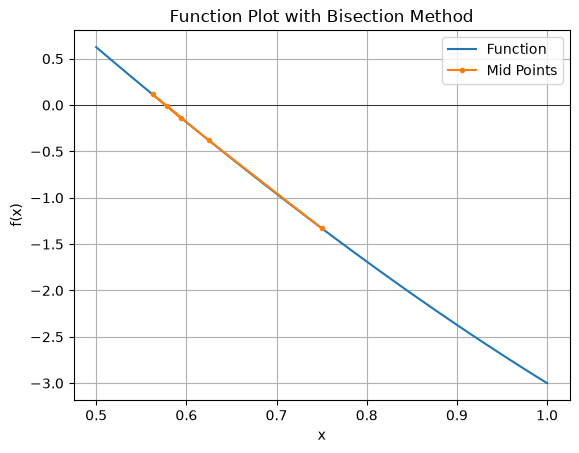

In [6]:
def Bisection( maxIterations: int , lowerLimit: float , upperLimit: float , precision: float , function: callable, verbose: bool = False, plotting = False ) -> float:
    if plotting:
        midPoints = []
        x = np.linspace(lowerLimit, upperLimit, 100)
        y = function(x)
        plt.plot(x, y, label='Function')
        plt.axhline(0, color='black', lw=0.5)
        plt.title('Function Plot with Bisection Method')
        plt.xlabel('x')
        plt.ylabel('f(x)')
        

    iteration: int = 0
    midPoint: float = 0.0
    previusMidPoint: float = 0.0
    functionAplicationLowerLimit: float = 0.0
    functionAplicationUpperLimit: float = 0.0
    functionAplicationMidPoint: float = 0.0
    relativeError: float = 0.0
    ans: float = 0.0

    if verbose:
        print(f"Iteration: {iteration}\n\tLower Limit: {lowerLimit:.5e}, Upper Limit: {upperLimit:.5e}, Mid Point: {midPoint:.5e}\n\tFunction at Lower Limit: {functionAplicationLowerLimit:.5e},Function at Upper Limit: {functionAplicationUpperLimit:.5e}, Function at Mid Point: {functionAplicationMidPoint:.5e}\n\tRelative Error: {relativeError:.5e}")
    
    while iteration < maxIterations:
        if abs( upperLimit - lowerLimit ) < precision:
            ans = (lowerLimit + upperLimit) / float(2)
            break

        previusMidPoint = midPoint
        midPoint = (lowerLimit + upperLimit) / float(2)
        functionAplicationLowerLimit = function(lowerLimit)
        functionAplicationUpperLimit = function(upperLimit)
        functionAplicationMidPoint = function(midPoint)

        if iteration > 0:
            relativeError = abs((midPoint - previusMidPoint) / midPoint)

        if plotting:
            midPoints.append(midPoint)

        if abs(functionAplicationMidPoint) < precision:
            ans = midPoint
            break  

        if functionAplicationLowerLimit * functionAplicationMidPoint > 0:
            lowerLimit = midPoint
        else:
            upperLimit = midPoint

        iteration += 1
        if verbose:
            print(f"Iteration: {iteration}\n\tLower Limit: {lowerLimit:.5e}, Upper Limit: {upperLimit:.5e}, Mid Point: {midPoint:.5e}\n\tFunction at Lower Limit: {functionAplicationLowerLimit:.5e},Function at Upper Limit: {functionAplicationUpperLimit:.5e}, Function at Mid Point: {functionAplicationMidPoint:.5e}\n\tRelative Error: {relativeError:.5e}")
    

    
    if iteration == maxIterations:
        print(f"Maximum iterations reached: {maxIterations}. The root may not have been found within the desired precision.")
        ans = (lowerLimit + upperLimit) / float(2)
    else:
        iteration += 1
        if midPoint != 0:
            relativeError = abs((midPoint - previusMidPoint) / midPoint)
        if verbose:
            print(f"Iteration: {iteration}\n\tLower Limit: {lowerLimit:.5e}, Upper Limit: {upperLimit:.5e}, Mid Point: {midPoint:.5e}\n\tFunction at Lower Limit: {functionAplicationLowerLimit:.5e},Function at Upper Limit: {functionAplicationUpperLimit:.5e}, Function at Mid Point: {functionAplicationMidPoint:.5e}\n\tRelative Error: {relativeError:.5e}")

    if verbose:
        print(f"Root found at: {ans:.5e} after {iteration} iterations with precision: {precision:.5e}")
    if plotting:    
        midPointsFx = [function(mid) for mid in midPoints]
        plt.plot(midPoints, midPointsFx, marker='.', label='Mid Points')
        plt.legend()
        plt.grid()
        plt.show()
    return ans

## Test Function

## [0.5,1] precision 0.01
function1: callable = lambda x: x**3 - (9 * x) + 5

root1: float = Bisection(100, 0.5, 1, 0.01, function1, verbose=True, plotting=True)

## False Position

**Characteristics:** Also a bracketing method, but uses the linear interpolation (secant line) between `(a, f(a))` and `(b, f(b))` instead of the midpoint. Keeps the sign-change guarantee of bisection while usually converging faster.

**Limitations:** One endpoint can get "stuck" and stop updating when the function is strongly curved/asymmetric near the root, slowing convergence toward linear. Still requires a valid bracket with opposite-sign endpoints.

**Best use:** Bracketed problems where the function is roughly linear near the root.

**Worst use:** Strongly curved/flat functions near the root (stalling), or no bracket available.


Iteration: 0
	Lower Limit: 0.00000e+00, Upper Limit: 1.00000e+00, Mid Point: 0.00000e+00
	Function at Lower Limit: 0.00000e+00, Function at Mid Point: 0.00000e+00, Function at Upper Limit: 0.00000e+00
	Relative Error: 0.00000e+00
Iteration: 1
	Lower Limit: 0.00000e+00, Upper Limit: 6.25000e-01, Mid Point: 6.25000e-01
	Function at Lower Limit: 5.00000e+00, Function at Mid Point: -3.80859e-01, Function at Upper Limit: -3.00000e+00
	Relative Error: 0.00000e+00
Iteration: 2
	Lower Limit: 0.00000e+00, Upper Limit: 5.80762e-01, Mid Point: 5.80762e-01
	Function at Lower Limit: 5.00000e+00, Function at Mid Point: -3.09780e-02, Function at Upper Limit: -3.80859e-01
	Relative Error: 7.61719e-02
Iteration: 3
	Lower Limit: 0.00000e+00, Upper Limit: 5.77186e-01, Mid Point: 5.77186e-01
	Function at Lower Limit: 5.00000e+00, Function at Mid Point: -2.39003e-03, Function at Upper Limit: -3.09780e-02
	Relative Error: 6.19560e-03
Iteration: 4
	Lower Limit: 0.00000e+00, Upper Limit: 5.77186e-01, Mid Poin

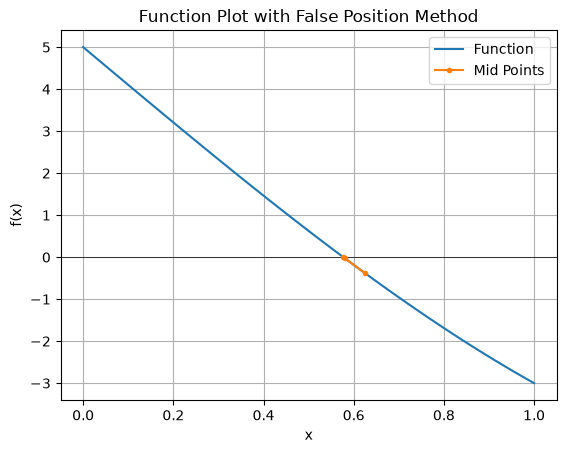

In [7]:
def FalsePosition( maxIterations: int , lowerLimit: float , upperLimit: float , precisionLimits: float, precisontFunction: float , function: callable, verbose: bool = False, plotting: bool = False ) -> float:
    if plotting:
        midPoints = []
        x = np.linspace(lowerLimit, upperLimit, 100)
        y = function(x)
        plt.plot(x, y, label='Function')
        plt.axhline(0, color='black', lw=0.5)
        plt.title('Function Plot with False Position Method')
        plt.xlabel('x')
        plt.ylabel('f(x)')

    
    iteration: int = 0
    midPoint: float = 0.0
    previusMidPoint: float = 0.0
    functionAplicationLowerLimit: float = 0.0
    functionAplicationUpperLimit: float = 0.0
    functionAplicationMidPoint: float = 0.0
    relativeError: float = 0.0
    ans: float = 0.0


    if verbose:
        print(f"Iteration: {iteration}\n\tLower Limit: {lowerLimit:.5e}, Upper Limit: {upperLimit:.5e}, Mid Point: {midPoint:.5e}\n\tFunction at Lower Limit: {functionAplicationLowerLimit:.5e}, Function at Mid Point: {functionAplicationMidPoint:.5e}, Function at Upper Limit: {functionAplicationUpperLimit:.5e}\n\tRelative Error: {relativeError:.5e}")
    
    while iteration < maxIterations:
        if abs( upperLimit - lowerLimit ) < precisionLimits:
            break

        functionAplicationLowerLimit = function(lowerLimit)
        functionAplicationUpperLimit = function(upperLimit)
        previusMidPoint = midPoint
        midPoint = ((lowerLimit * functionAplicationUpperLimit) - (upperLimit * functionAplicationLowerLimit)) / (functionAplicationUpperLimit - functionAplicationLowerLimit)
        functionAplicationMidPoint = function(midPoint)

        if iteration > 0:  
            relativeError = abs((midPoint - previusMidPoint) / midPoint)

        if abs(functionAplicationMidPoint) < precisontFunction:
            ans = midPoint
            break
              
        if abs(functionAplicationLowerLimit) < precisontFunction:
            if plotting:    
                midPoints.append(lowerLimit)
            ans = lowerLimit
            break
            
        if abs(functionAplicationUpperLimit) < precisontFunction:
            if plotting:    
                midPoints.append(upperLimit)
            ans = upperLimit
            break

        if plotting:
            midPoints.append(midPoint)

        if functionAplicationLowerLimit * functionAplicationMidPoint > 0:
            lowerLimit = midPoint
        else:
            upperLimit = midPoint

        iteration += 1
        if verbose:
            print(f"Iteration: {iteration}\n\tLower Limit: {lowerLimit:.5e}, Upper Limit: {upperLimit:.5e}, Mid Point: {midPoint:.5e}\n\tFunction at Lower Limit: {functionAplicationLowerLimit:.5e}, Function at Mid Point: {functionAplicationMidPoint:.5e}, Function at Upper Limit: {functionAplicationUpperLimit:.5e}\n\tRelative Error: {relativeError:.5e}")

    
    if iteration == maxIterations:
        print(f"Maximum iterations reached: {maxIterations}. The root may not have been found within the desired precision.")
        midPoint = (lowerLimit + upperLimit) / float(2)
        midPoints.append(midPoint)
        ans = midPoints
    else:
        iteration += 1
        if midPoint != 0:
            relativeError = abs((midPoint - previusMidPoint) / midPoint)
        if verbose:
            print(f"Iteration: {iteration}\n\tLower Limit: {lowerLimit:.5e}, Upper Limit: {upperLimit:.5e}, Mid Point: {midPoint:.5e}\n\tFunction at Lower Limit: {functionAplicationLowerLimit:.5e}, Function at Mid Point: {functionAplicationMidPoint:.5e}, Function at Upper Limit: {functionAplicationUpperLimit:.5e}\n\tRelative Error: {relativeError:.5e}")
    if verbose:
        print(f"Root found at: {ans:.5e} after {iteration} iterations with precision limit: {precisionLimits:.5e} and precision for function: {precisontFunction:.5e}")
    
    if plotting:    
        midPointsFx = [function(mid) for mid in midPoints]
        plt.plot(midPoints, midPointsFx, marker='.', label='Mid Points')
        plt.legend()
        plt.grid()
        plt.show()
    return ans



## Test Function

## [0,1] precision 5e-4
functionFalsePosition: callable = lambda x: x**3 - (9 * x) + 5

rootFalsePosition: float = FalsePosition(100, 0, 1, 5e-4 , 5e-4 , functionFalsePosition, verbose=True, plotting=True)

## Newton-Raphson

**Characteristics:** Uses the function and its derivative to extrapolate a tangent line to the next estimate; converges quadratically near the root. Only needs a single initial guess, not a bracket.

**Limitations:** Requires the derivative `f'(x)` to be known/computable. Can diverge, cycle, or converge to the wrong root with a poor initial guess or near-zero derivative. No sign-change safeguard.

**Best use:** Smooth functions with an easy-to-compute derivative and a good initial guess close to the root.

**Worst use:** Unknown/expensive derivatives, near-zero derivative regions, inflection points, or multiple close roots.


Iteration: 0, Current Estimate: 7.50000e-01
Iteration: 1
	Current Estimate: 7.50000e-01, Next Estimate: 5.68376e-01
	Function at Current Estimate: -1.32812e+00, Function Prime at Current Estimate: -7.31250e+00
	Relative Error: 0.00000e+00
Iteration: 2
	Current Estimate: 5.68376e-01, Next Estimate: 5.76872e-01
	Function at Current Estimate: 6.82300e-02, Function Prime at Current Estimate: -8.03085e+00
	Relative Error: 1.47277e-02
Iteration: 3
	Current Estimate: 5.68376e-01, Next Estimate: 5.76872e-01
	Function at Current Estimate: 6.82300e-02, Function Prime at Current Estimate: -8.03085e+00
	Relative Error: 1.47277e-02
Root found at: 5.76872e-01 after 3 iterations with precision difference: 1.00000e-02 and precision point: 1.00000e-02


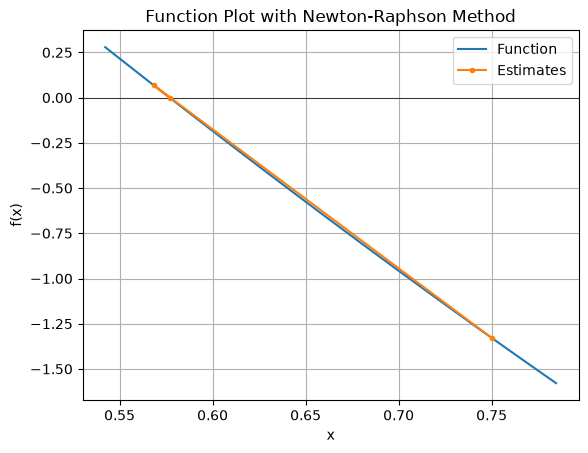

In [8]:
def NewtonRaphson( maxIterations: int , initialEstimate: float , precisionDifference: float , precisionPoint: float , function: callable , functionPrime: callable, verbose: bool = False, plotting: bool = False ) -> float:

    if plotting:
        estimates = []
        initialPoint = initialEstimate
        plt.axhline(0, color='black', lw=0.5)
        plt.title('Function Plot with Newton-Raphson Method')
        plt.xlabel('x')
        plt.ylabel('f(x)')

    iteration: int = 0
    previousEstimate: float = initialEstimate
    estimate: float = 0.0
    relativeError: float = 0.0
    ans: float = 0.0     
        
    if verbose:
        print(f"Iteration: {iteration}, Current Estimate: {previousEstimate:.5e}")

    while iteration < maxIterations:
        if abs(function(previousEstimate)) < precisionPoint:
            if plotting:
                estimates.append(previousEstimate)
            ans = previousEstimate
            break
        
        estimate = previousEstimate - (function(previousEstimate) / functionPrime(previousEstimate))    
        if iteration > 0:
            relativeError = abs((estimate - previousEstimate) / estimate)

        iteration += 1
        if plotting:
            estimates.append(previousEstimate)

        if verbose:
            print(f"Iteration: {iteration}\n\tCurrent Estimate: {previousEstimate:.5e}, Next Estimate: {estimate:.5e}\n\tFunction at Current Estimate: {function(previousEstimate):.5e}, Function Prime at Current Estimate: {functionPrime(previousEstimate):.5e}\n\tRelative Error: {relativeError:.5e}")

        if abs(estimate - previousEstimate) < precisionDifference or abs(function(estimate)) < precisionPoint:
            if plotting:
                estimates.append(estimate)
            ans = estimate 
            break

        previousEstimate = estimate


    if iteration == maxIterations:
        print(f"Maximum iterations reached: {maxIterations}. The root may not have been found within the desired precision.")
    else:
        iteration += 1
        if estimate != 0:
            relativeError = abs((estimate - previousEstimate) / estimate)
        if verbose:
            print(f"Iteration: {iteration}\n\tCurrent Estimate: {previousEstimate:.5e}, Next Estimate: {estimate:.5e}\n\tFunction at Current Estimate: {function(previousEstimate):.5e}, Function Prime at Current Estimate: {functionPrime(previousEstimate):.5e}\n\tRelative Error: {relativeError:.5e}")
    if verbose:
        print(f"Root found at: {ans:.5e} after {iteration} iterations with precision difference: {precisionDifference:.5e} and precision point: {precisionPoint:.5e}")

    if plotting:
        delta = abs(0.2 *(initialPoint - estimate))
        if estimate > initialPoint:
            x = np.linspace( initialPoint - delta , estimate + delta , 100)
        else:
            x = np.linspace( estimate - delta , initialPoint + delta , 100)
        y = function(x)
        plt.plot(x, y, label='Function')
        estimatesFx = [function(mid) for mid in estimates]
        plt.plot(estimates, estimatesFx, marker='.', label='Estimates')
        plt.legend()
        plt.grid()
        plt.show()

    return ans
## Test Function

## initial estimate 0.75 precision 1e-2
functionNewton: callable = lambda x: x**3 - (9 * x) + 5
functionNewtonPrime: callable = lambda x: 3 * (x**2) - 9

    
root1: float = NewtonRaphson(100, 0.75, 1e-2, 1e-2, functionNewton, functionNewtonPrime, verbose=True, plotting=True)

## Secant

**Characteristics:** Like Newton-Raphson but replaces the derivative with a finite-difference approximation from the last two estimates — no analytic derivative needed. Superlinear convergence (order ≈ 1.618).

**Limitations:** Needs two initial estimates (not necessarily bracketing). Can diverge if estimates are far from the root or the function is near-flat between them. No bracket safeguard.

**Best use:** Smooth functions where the derivative is unavailable/costly, with reasonable initial estimates.

**Worst use:** Poorly-behaved/noisy functions, or widely-spaced/poor initial guesses.

Iteration: 0
	Initial Estimate One: 0.00000e+00, Function at: 3.00000e+00
	Initial Estimate Two: 1.00000e+00, Function at: -5.00000e+00
	Estimate: 0.00000e+00, Function at Estimate: NILL
	, Relative Error: 0.00000e+00
Iteration: 1
	Initial Estimate One: 0.00000e+00, Function at: 3.00000e+00
	Initial Estimate Two: 1.00000e+00, Function at: -5.00000e+00
	Estimate: 3.75000e-01, Function at Estimate: -3.22266e-01
	Relative Error: 1.66667e+00
Iteration: 2
	Initial Estimate One: 1.00000e+00, Function at: -5.00000e+00
	Initial Estimate Two: 3.75000e-01, Function at: -3.22266e-01
	Estimate: 3.31942e-01, Function at Estimate: 4.91011e-02
	Relative Error: 1.29717e-01
Iteration: 3
	Initial Estimate One: 3.75000e-01, Function at: -3.22266e-01
	Initial Estimate Two: 3.31942e-01, Function at: 4.91011e-02
	Estimate: 3.37635e-01, Function at Estimate: -2.22206e-04
	Relative Error: 1.68616e-02
Root found at: 3.37635e-01 after 3 iterations with precision difference: 5.00000e-04 and precision point: 5.00

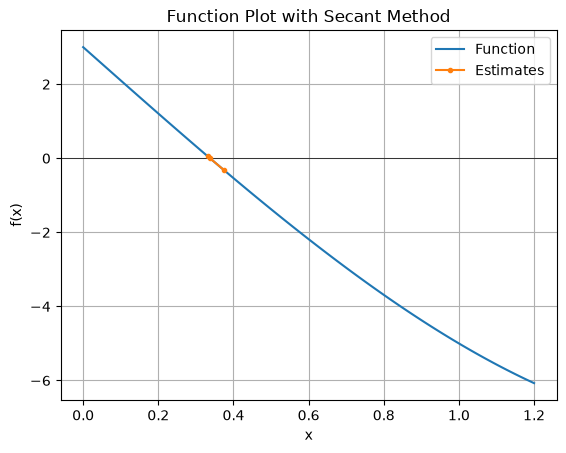

In [9]:
def Secant( maxIterations: int , initialEstimateOne: float , initialEstimateTwo: float , precisionDifference: float , precisionPoint: float , function: callable , verbose: bool = False , plotting: bool = False ) -> float:

    if plotting:
        estimates = []
        initialPointOne = initialEstimateOne
        initialPointTwo = initialEstimateTwo
        plt.axhline(0, color='black', lw=0.5)
        plt.title('Function Plot with Secant Method')
        plt.xlabel('x')
        plt.ylabel('f(x)')

    iteration: int = 0
    previousEstimateOne: float = initialEstimateOne
    previousEstimateTwo: float = initialEstimateTwo
    estimateOne: float = function(previousEstimateOne)
    estimateTwo: float = function(previousEstimateTwo)
    estimate: float = 0.0
    relativeError: float = 0.0
    ans: float = 0

    if verbose:
        print(f"Iteration: {iteration}\n\tInitial Estimate One: {previousEstimateOne:.5e}, Function at: {estimateOne:.5e}\n\tInitial Estimate Two: {previousEstimateTwo:.5e}, Function at: {estimateTwo:.5e}\n\tEstimate: {estimate:.5e}, Function at Estimate: NILL\n\t, Relative Error: {relativeError:.5e}")


    while iteration < maxIterations:
        if abs(estimateOne) < precisionPoint or abs(previousEstimateTwo - previousEstimateOne) < precisionDifference:
            ans = previousEstimateOne
            if plotting:
                estimates.append(previousEstimateOne)
            break

        estimate = previousEstimateTwo - ( estimateTwo * (previousEstimateTwo - previousEstimateOne) ) / (estimateTwo - estimateOne)
        if plotting:
            estimates.append(estimate)


        if abs(estimate - previousEstimateTwo) < precisionDifference or abs(function(estimate)) < precisionPoint:
            ans = estimate
            break

        relativeError = abs((estimate - previousEstimateTwo) / estimate)

        iteration += 1
        if verbose:
            print(f"Iteration: {iteration}\n\tInitial Estimate One: {previousEstimateOne:.5e}, Function at: {estimateOne:.5e}\n\tInitial Estimate Two: {previousEstimateTwo:.5e}, Function at: {estimateTwo:.5e}\n\tEstimate: {estimate:.5e}, Function at Estimate: {function(estimate):.5e}\n\tRelative Error: {relativeError:.5e}")

        previousEstimateOne = previousEstimateTwo
        previousEstimateTwo = estimate
        estimateOne = estimateTwo
        estimateTwo = function(estimate)
        
    if iteration == maxIterations:
        print(f"Maximum iterations reached: {maxIterations}. The root may not have been found within the desired precision.")
        ans = estimate
    else:
        iteration += 1
        relativeError = abs((estimate - previousEstimateTwo) / estimate)
        if verbose:
            print(f"Iteration: {iteration}\n\tInitial Estimate One: {previousEstimateOne:.5e}, Function at: {estimateOne:.5e}\n\tInitial Estimate Two: {previousEstimateTwo:.5e}, Function at: {estimateTwo:.5e}\n\tEstimate: {estimate:.5e}, Function at Estimate: {function(estimate):.5e}\n\tRelative Error: {relativeError:.5e}")
    if verbose:
        print(f"Root found at: {ans:.5e} after {iteration} iterations with precision difference: {precisionDifference:.5e} and precision point: {precisionPoint:.5e}")

    if plotting:
        if initialPointOne > initialPointTwo:
            x = np.linspace( initialPointTwo * 0.8 , initialPointOne * 1.2 , 100)
        else:
            x = np.linspace( initialPointOne * 0.8 , initialPointTwo * 1.2 , 100)
        y = function(x)
        plt.plot(x, y, label='Function')
        estimatesFx = [function(mid) for mid in estimates]
        plt.plot(estimates, estimatesFx, marker='.', label='Estimates')
        plt.legend()
        plt.grid()
        plt.show()


    return ans

## Test Function

## initial estimate 0.75 precision 1e-2
functionSecant: callable = lambda x: x**3 - (9 * x) + 3

    
root1: float = Secant(100, 0 , 1, 5e-4, 5e-4, functionSecant, verbose=True, plotting=True)

# Foward and Backward Substitution


In [10]:
def FBSubstitution( L: np.array, U: np.array, pivots: np.array, B: np.array, pivoting: bool = False ) -> np.array:
    matrixSize = L.shape[0]
    y = np.zeros(matrixSize, dtype=float)

    B_permutated = np.zeros(matrixSize, dtype=float)
    if pivoting:
        for index in range(matrixSize):
            B_permutated[index] = B[pivots[index]]
    else:
        B_permutated = B.copy()

    for row in range(matrixSize):
        sum_L = 0.0
        for column in range(row):
            sum_L += L[row, column] * y[column]
        y[row] = (B_permutated[row] - sum_L) / L[row, row]

    vectorSolution = np.zeros(matrixSize, dtype=float)

    for row in range(matrixSize - 1, -1, -1):
        sum_U = 0.0
        for column in range(row + 1, matrixSize):
            sum_U += U[row, column] * vectorSolution[column]
        vectorSolution[row] = (y[row] - sum_U) / U[row, row]
    
    return vectorSolution

# LU Decomposition

In [11]:
def LuDecomposition( A: np.array ) -> tuple:
    A = np.array(A, dtype=float)  # copy, avoids mutating input
    matrixSize = A.shape[0]
    if A.shape[1] != matrixSize:
        raise ValueError("Matrix A must be square.")
    
    L = np.eye(matrixSize, dtype=float)
    U = np.zeros((matrixSize, matrixSize), dtype=float)
    pivot = np.zeros(matrixSize, dtype=int)
    for i in range(matrixSize):
        pivot[i] = i
    pDU = 1
    info = 0


    for activeColumn in range(matrixSize): # activeColumn == j

        lagestValue = activeColumn # p
        for inspector in range(activeColumn + 1, matrixSize): # inspector == k
            if abs(A[inspector, activeColumn]) > abs(A[lagestValue, activeColumn]):
                lagestValue = inspector

        if activeColumn != lagestValue:
            A[[activeColumn, lagestValue], :] = A[[lagestValue, activeColumn], :]
            
            temp_p = pivot[activeColumn]
            pivot[activeColumn] = pivot[lagestValue]
            pivot[lagestValue] = temp_p
            
            pDU = -pDU
        
        pDU *= A[activeColumn, activeColumn]

        if A[activeColumn, activeColumn] != 0:
            ratio = 1.0 / A[activeColumn, activeColumn]
            for row in range(activeColumn + 1, matrixSize):
                mult = A[row, activeColumn] * ratio
                A[row, activeColumn] = mult
                for column in range(activeColumn + 1, matrixSize):
                    A[row, column] -= mult * A[activeColumn, column]
        else:
            info = activeColumn + 1
            
            
    for row in range(matrixSize):
        for column in range(matrixSize):
            if row > column:
                L[row, column] = A[row, column]
            else:
                U[row, column] = A[row, column]

    return A, L, U, pivot, pDU, info


matrixInput = np.array([[0, 1, -2], [2, -2, 3], [1, 3, 1]], dtype=float)

A, L, U, pivot, pDU, info = LuDecomposition(matrixInput)

print("A:\n", A)
print("L:\n", L)
print("U:\n", U)
print("Pivot:\n", pivot)

result = FBSubstitution(L, U, pivot, np.array([7, -10, 8], dtype=float), pivoting=True)

print("Vector Solution:\n", result)

"""
Wanted Result

A:
 [[ 2.    -2.     3.   ]
 [ 0.5    4.    -0.5  ]
 [ 0.     0.25  -1.875]]
L:
 [[1.   0.   0.  ]
 [0.5  1.   0.  ]
 [0.   0.25 1.  ]]
U:
 [[ 2.    -2.     3.   ]
 [ 0.     4.    -0.5  ]
 [ 0.     0.    -1.875]]
Pivot:
 [1 2 0] 
Vector Solution:
 [ 1.  3. -2.]
"""


A:
 [[ 2.    -2.     3.   ]
 [ 0.5    4.    -0.5  ]
 [ 0.     0.25  -1.875]]
L:
 [[1.   0.   0.  ]
 [0.5  1.   0.  ]
 [0.   0.25 1.  ]]
U:
 [[ 2.    -2.     3.   ]
 [ 0.     4.    -0.5  ]
 [ 0.     0.    -1.875]]
Pivot:
 [1 2 0]
Vector Solution:
 [ 1.  3. -2.]


'\nWanted Result\n\nA:\n [[ 2.    -2.     3.   ]\n [ 0.5    4.    -0.5  ]\n [ 0.     0.25  -1.875]]\nL:\n [[1.   0.   0.  ]\n [0.5  1.   0.  ]\n [0.   0.25 1.  ]]\nU:\n [[ 2.    -2.     3.   ]\n [ 0.     4.    -0.5  ]\n [ 0.     0.    -1.875]]\nPivot:\n [1 2 0] \nVector Solution:\n [ 1.  3. -2.]\n'

# Cholesky Decomposition

In [12]:
def CholeskyDecomposition( A: np.array ) -> tuple:
    A = np.array(A, dtype=float)  # copy, avoids mutating input
    matrixSize = A.shape[0]

    determinant = 1.0
    info = 0

    if A.shape[1] != matrixSize:
        raise ValueError("Matrix A must be square.")

    for j in range(matrixSize):
        sums = 0
        for k in range(j):
            sums += A[j, k] ** 2
        temp = A[j, j] - sums
        if temp > 0:
            A[j, j] = math.sqrt(temp)
            r = 1.0 / A[j, j]
            determinant *= temp
        else:
            info = j + 1
            raise ValueError("Matrix A is not positive definite.")
        for i in range(j + 1, matrixSize):
            sums = 0
            for k in range(j):
                sums = sums + A[i, k] * A[j, k]
            A[i, j] = (A[i, j] - sums) * r

    return A, np.tril(A), determinant, info



matrixInput = np.array([[4, 12, -16], [12, 37, -43], [-16, -43, 98]], dtype=float)

A, L, determinant, info = CholeskyDecomposition(matrixInput)

b = np.array([-20, -43, 192])

vectorsolution = FBSubstitution(L, L.T, None, b, pivoting=False)

print("A:\n", A)
print("L:\n", L)
print("Vector Solution:\n", vectorsolution)
print("Determinant:\n", determinant)
print("Info:\n", info)


""" 
Wanted results

L = [[ 2, 0, 0],
     [ 6, 1, 0],
     [-8, 5, 3]]
vectorsolution = [1, 2, 3]
determinant = 36

"""


A:
 [[  2.  12. -16.]
 [  6.   1. -43.]
 [ -8.   5.   3.]]
L:
 [[ 2.  0.  0.]
 [ 6.  1.  0.]
 [-8.  5.  3.]]
Vector Solution:
 [1. 2. 3.]
Determinant:
 36.0
Info:
 0


' \nWanted results\n\nL = [[ 2, 0, 0],\n     [ 6, 1, 0],\n     [-8, 5, 3]]\nvectorsolution = [1, 2, 3]\ndeterminant = 36\n\n'

# Gauss-Jacobi 

In [13]:
def GaussJacobi(A: np.array, b: np.array, maxIterations: int, precision: float, verbose: bool = False) -> np.array:
    matrixSize = A.shape[0]
    v = np.zeros(matrixSize, dtype=float)
    vectorSolution = np.zeros(matrixSize, dtype=float)
    iterations = 0
    info = 0


    if A.shape[1] != matrixSize:
        raise ValueError("Matrix A must be square.")

    for i in range(matrixSize):
        vectorSolution[i] = b[i] / A[i, i]

    while True:
        iterations += 1
        for i in range(matrixSize):
            sumAx = 0.0
            for j in range(matrixSize):
                if i != j:
                    sumAx += A[i, j] * vectorSolution[j]
            v[i] = (b[i] - sumAx) / A[i, i]
        normaNum = 0.0
        normoDen = 0.0

        for i in range(matrixSize):
            t = abs(v[i] - vectorSolution[i])
            if t > normaNum:
                normaNum = t
            if abs(v[i]) > normoDen:
                normoDen = abs(v[i])
            vectorSolution[i] = v[i] 
        normaRel = normaNum / normoDen

        print(f"Iteration: {iterations}, Norma Relative: {normaRel:.5e}, Vector Solution: {vectorSolution}")

        if (iterations >= maxIterations) or (normaRel <= precision):
            if iterations >= maxIterations:
                info = 0
            else:
                info = 1
            break
    
    return vectorSolution, iterations, info




A = np.array([[4, 1, 1], [1, 5, 2], [1, 2, 6]], dtype=float)
b = np.array([9, 17, 23], dtype=float)
Toler = 1e-20
IterMax = 200

vectorsolution, iters, info = GaussJacobi(A, b, IterMax, Toler, verbose=True)

print("Vector Solution:\n", vectorsolution)


# Result = [ 1 , 2 , 3 ]

Iteration: 1, Norma Relative: 8.53047e-01, Vector Solution: [0.44166667 1.41666667 2.325     ]
Iteration: 2, Norma Relative: 2.93536e-01, Vector Solution: [1.31458333 2.38166667 3.2875    ]
Iteration: 3, Norma Relative: 1.98409e-01, Vector Solution: [0.83270833 1.82208333 2.82034722]
Iteration: 4, Norma Relative: 9.17457e-02, Vector Solution: [1.08939236 2.10531944 3.0871875 ]
Iteration: 5, Norma Relative: 5.35841e-02, Vector Solution: [0.95187326 1.94724653 2.94999479]
Iteration: 6, Norma Relative: 2.72279e-02, Vector Solution: [1.02568967 2.02962743 3.02560561]
Iteration: 7, Norma Relative: 1.50737e-02, Vector Solution: [0.98619174 1.98461982 2.98584258]
Iteration: 8, Norma Relative: 7.91533e-03, Vector Solution: [1.0073844  2.00842462 3.0074281 ]
Iteration: 9, Norma Relative: 4.29670e-03, Vector Solution: [0.99603682 1.99555188 2.99596106]
Iteration: 10, Norma Relative: 2.28381e-03, Vector Solution: [1.00212177 2.00240821 3.00214324]
Iteration: 11, Norma Relative: 1.23043e-03, Vecto

# Gauss-Seidel

In [14]:
def GaussSeidel(A: np.array, b: np.array, maxIterations: int, precision: float, verbose: bool = False) -> np.array:
    matrixSize = A.shape[0]
    v = np.zeros(matrixSize, dtype=float)
    vectorSolution = np.zeros(matrixSize, dtype=float)
    iterations = 0
    info = 0


    if A.shape[1] != matrixSize:
        raise ValueError("Matrix A must be square.")

    for i in range(matrixSize):
        vectorSolution[i] = b[i] / A[i, i]

    while True:
        iterations += 1
        normaNum = 0.0
        normoDen = 0.0
        for i in range(matrixSize):
            sumAx = 0.0
            for j in range(matrixSize):
                if i != j:
                    sumAx += A[i, j] * vectorSolution[j]
            v[i] = vectorsolution[i]
            vectorSolution[i] = (b[i] - sumAx) / A[i, i]
            t = abs(v[i] - vectorSolution[i])
            if t > normaNum:
                normaNum = t
            if abs(vectorSolution[i]) > normoDen:
                normoDen = abs(vectorSolution[i])
        normaRel = normaNum / normoDen

        print(f"Iteration: {iterations}, Norma Relative: {normaRel:.5e}, Vector Solution: {vectorSolution}")

        if (iterations >= maxIterations) or (normaRel <= precision):
            if iterations >= maxIterations:
                info = 0
            else:
                info = 1
            break
    return vectorSolution, iterations, info




A = np.array([[4, 1, 1], [1, 5, 2], [1, 2, 6]], dtype=float)
b = np.array([9, 17, 23], dtype=float)
Toler = 1e-20
IterMax = 200

vectorsolution, iters, info = GaussSeidel(A, b, IterMax, Toler, verbose=True)

print("Vector Solution:\n", vectorsolution)


# Result = [ 1 , 2 , 3 ]

Iteration: 1, Norma Relative: 1.76300e-01, Vector Solution: [0.44166667 1.77833333 3.16694444]
Iteration: 2, Norma Relative: 2.30111e-02, Vector Solution: [1.01368056 1.93048611 3.0208912 ]
Iteration: 3, Norma Relative: 4.04977e-03, Vector Solution: [1.01215567 1.98921238 3.00156993]
Iteration: 4, Norma Relative: 7.68146e-04, Vector Solution: [1.00230442 1.99891114 2.99997888]
Iteration: 5, Norma Relative: 9.24988e-05, Vector Solution: [1.00027749 1.99995295 2.99996943]
Iteration: 6, Norma Relative: 6.46805e-06, Vector Solution: [1.0000194  2.00000835 2.99999398]
Iteration: 7, Norma Relative: 8.40927e-07, Vector Solution: [0.99999942 2.00000252 2.99999926]
Iteration: 8, Norma Relative: 1.48243e-07, Vector Solution: [0.99999956 2.00000039 2.99999995]
Iteration: 9, Norma Relative: 2.76486e-08, Vector Solution: [0.99999992 2.00000004 3.        ]
Iteration: 10, Norma Relative: 3.28940e-09, Vector Solution: [0.99999999 2.         3.        ]
Iteration: 11, Norma Relative: 2.24482e-10, Vecto

# Newton

In [15]:
def Newton( F: callable , J: callable , x0: np.array , precision: float = 1e-10 , maxIterations: int = 100 ) -> tuple:
    vectorSolution = np.array(x0, dtype=float)
    iterations = 0
    info = 0
    while True:
        Jx = J(vectorSolution)
        Fx = F(vectorSolution)

        if np.linalg.norm(Fx, np.inf) <= precision:
            info = 1
            break

        try:
            s = np.linalg.solve(Jx, -Fx)
        except np.linalg.LinAlgError:
            info = 2
            break
        vectorSolution = vectorSolution + s

        iterations += 1
        
        print(f"Iteration: {iterations}, Vector Solution: {vectorSolution}, ||F(x)||_inf: {np.linalg.norm(Fx, np.inf):.5e}")

        if np.linalg.norm(s, np.inf) <= precision:
            info = 1
            break

        
        if iterations >= maxIterations:
            info = 0
            break
    return vectorSolution, iterations, info

F = lambda x: np.array([3*x[0] - np.cos(x[1]*x[2]) - 0.5, x[0]**2 - 81*(x[1]+0.1)**2 + np.sin(x[2]) + 1.06, np.exp(-x[0]*x[1]) + 20*x[2] + (10*np.pi - 3)/3])

J = lambda x: np.array([[3, x[2]*np.sin(x[1]*x[2]), x[1]*np.sin(x[1]*x[2])], [2*x[0], -162*(x[1]+0.1), np.cos(x[2])], [-x[1]*np.exp(-x[0]*x[1]), -x[0]*np.exp(-x[0]*x[1]), 20]])

vectorSolution, iterations, info = Newton(F, J, np.array([0.1, 0.1, -0.1]), precision=1e-10, maxIterations=100)

print("Vector Solution:\n", vectorSolution)

        

Iteration: 1, Vector Solution: [ 0.49986967  0.01946685 -0.52152047], ||F(x)||_inf: 8.46203e+00
Iteration: 2, Vector Solution: [ 0.50001424  0.00158859 -0.52355696], ||F(x)||_inf: 3.44388e-01
Iteration: 3, Vector Solution: [ 5.00000113e-01  1.24447833e-05 -5.23598450e-01], ||F(x)||_inf: 2.58891e-02
Iteration: 4, Vector Solution: [ 5.00000000e-01  7.75785716e-10 -5.23598776e-01], ||F(x)||_inf: 2.01223e-04
Iteration: 5, Vector Solution: [ 5.00000000e-01  3.35521889e-18 -5.23598776e-01], ||F(x)||_inf: 1.25431e-08
Vector Solution:
 [ 5.00000000e-01  3.35521889e-18 -5.23598776e-01]


# Modified Newton

In [16]:
def ModifiedNewton( F: callable , J: callable , x0: np.array , precision: float = 1e-10 , maxIterations: int = 100 ) -> tuple:
    vectorSolution = np.array(x0, dtype=float)
    iterations = 0
    info = 0
    Jx0 = J(vectorSolution)

    while True:
        Fx = F(vectorSolution)

        if np.linalg.norm(Fx, np.inf) <= precision:
            info = 1
            break

        try:
            s = np.linalg.solve(Jx0, -Fx)
        except np.linalg.LinAlgError:
            info = 2
            break
        vectorSolution = vectorSolution + s

        iterations += 1
        
        print(f"Iteration: {iterations}, Vector Solution: {vectorSolution}, ||F(x)||_inf: {np.linalg.norm(Fx, np.inf):.5e}")

        if np.linalg.norm(s, np.inf) <= precision:
            info = 1
            break

        
        if iterations >= maxIterations:
            info = 0
            break
    return vectorSolution, iterations, info

F = lambda x: np.array([3*x[0] - np.cos(x[1]*x[2]) - 0.5, x[0]**2 - 81*(x[1]+0.1)**2 + np.sin(x[2]) + 1.06, np.exp(-x[0]*x[1]) + 20*x[2] + (10*np.pi - 3)/3])

J = lambda x: np.array([[3, x[2]*np.sin(x[1]*x[2]), x[1]*np.sin(x[1]*x[2])], [2*x[0], -162*(x[1]+0.1), np.cos(x[2])], [-x[1]*np.exp(-x[0]*x[1]), -x[0]*np.exp(-x[0]*x[1]), 20]])

vectorSolution, iterations, info = ModifiedNewton(F, J, np.array([0.1, 0.1, -0.1]), precision=1e-10, maxIterations=100)

print("Vector Solution:\n", vectorSolution)

Iteration: 1, Vector Solution: [ 0.49986967  0.01946685 -0.52152047], ||F(x)||_inf: 8.46203e+00
Iteration: 2, Vector Solution: [ 0.49998583  0.00878775 -0.52316688], ||F(x)||_inf: 3.44388e-01
Iteration: 3, Vector Solution: [ 0.49999793  0.00420477 -0.5234022 ], ||F(x)||_inf: 1.48257e-01
Iteration: 4, Vector Solution: [ 0.49999987  0.00206025 -0.52350437], ||F(x)||_inf: 6.93812e-02
Iteration: 5, Vector Solution: [ 0.50000014  0.00102056 -0.52355244], ||F(x)||_inf: 3.36382e-02
Iteration: 6, Vector Solution: [ 5.00000115e-01  5.08200199e-04 -5.23575805e-01], ||F(x)||_inf: 1.65771e-02
Iteration: 7, Vector Solution: [ 5.00000069e-01  2.53717695e-04 -5.23587332e-01], ||F(x)||_inf: 8.23375e-03
Iteration: 8, Vector Solution: [ 5.00000037e-01  1.26829787e-04 -5.23593061e-01], ||F(x)||_inf: 4.10546e-03
Iteration: 9, Vector Solution: [ 5.00000019e-01  6.34407076e-05 -5.23595919e-01], ||F(x)||_inf: 2.05096e-03
Iteration: 10, Vector Solution: [ 5.00000010e-01  3.17433466e-05 -5.23597347e-01], ||F(x

# Lagrange

In [17]:
def Lagrange( F: callable , J: callable , x0: np.array , precision: float = 1e-10 , maxIterations: int = 100 ) -> tuple:
    vectorSolution = np.array(x0, dtype=float)
    iterations = 0
    info = 0
    Jx0 = J(vectorSolution)

    while True:
        Fx = F(vectorSolution)

        if np.linalg.norm(Fx, np.inf) <= precision:
            info = 1
            break

        try:
            s = np.linalg.solve(Jx0, -Fx)
        except np.linalg.LinAlgError:
            info = 2
            break
        vectorSolution = vectorSolution + s

        iterations += 1
        
        print(f"Iteration: {iterations}, Vector Solution: {vectorSolution}, ||F(x)||_inf: {np.linalg.norm(Fx, np.inf):.5e}")

        if np.linalg.norm(s, np.inf) <= precision:
            info = 1
            break

        
        if iterations >= maxIterations:
            info = 0
            break
    return vectorSolution, iterations, info

F = lambda x: np.array([3*x[0] - np.cos(x[1]*x[2]) - 0.5, x[0]**2 - 81*(x[1]+0.1)**2 + np.sin(x[2]) + 1.06, np.exp(-x[0]*x[1]) + 20*x[2] + (10*np.pi - 3)/3])

J = lambda x: np.array([[3, x[2]*np.sin(x[1]*x[2]), x[1]*np.sin(x[1]*x[2])], [2*x[0], -162*(x[1]+0.1), np.cos(x[2])], [-x[1]*np.exp(-x[0]*x[1]), -x[0]*np.exp(-x[0]*x[1]), 20]])

vectorSolution, iterations, info = ModifiedNewton(F, J, np.array([0.1, 0.1, -0.1]), precision=1e-10, maxIterations=100)

print("Vector Solution:\n", vectorSolution)

Iteration: 1, Vector Solution: [ 0.49986967  0.01946685 -0.52152047], ||F(x)||_inf: 8.46203e+00
Iteration: 2, Vector Solution: [ 0.49998583  0.00878775 -0.52316688], ||F(x)||_inf: 3.44388e-01
Iteration: 3, Vector Solution: [ 0.49999793  0.00420477 -0.5234022 ], ||F(x)||_inf: 1.48257e-01
Iteration: 4, Vector Solution: [ 0.49999987  0.00206025 -0.52350437], ||F(x)||_inf: 6.93812e-02
Iteration: 5, Vector Solution: [ 0.50000014  0.00102056 -0.52355244], ||F(x)||_inf: 3.36382e-02
Iteration: 6, Vector Solution: [ 5.00000115e-01  5.08200199e-04 -5.23575805e-01], ||F(x)||_inf: 1.65771e-02
Iteration: 7, Vector Solution: [ 5.00000069e-01  2.53717695e-04 -5.23587332e-01], ||F(x)||_inf: 8.23375e-03
Iteration: 8, Vector Solution: [ 5.00000037e-01  1.26829787e-04 -5.23593061e-01], ||F(x)||_inf: 4.10546e-03
Iteration: 9, Vector Solution: [ 5.00000019e-01  6.34407076e-05 -5.23595919e-01], ||F(x)||_inf: 2.05096e-03
Iteration: 10, Vector Solution: [ 5.00000010e-01  3.17433466e-05 -5.23597347e-01], ||F(x

# Newton

In [18]:
def Newton( F: callable , J: callable , x0: np.array , precision: float = 1e-10 , maxIterations: int = 100 ) -> tuple:
    vectorSolution = np.array(x0, dtype=float)
    iterations = 0
    info = 0
    Jx0 = J(vectorSolution)

    while True:
        Fx = F(vectorSolution)

        if np.linalg.norm(Fx, np.inf) <= precision:
            info = 1
            break

        try:
            s = np.linalg.solve(Jx0, -Fx)
        except np.linalg.LinAlgError:
            info = 2
            break
        vectorSolution = vectorSolution + s

        iterations += 1
        
        print(f"Iteration: {iterations}, Vector Solution: {vectorSolution}, ||F(x)||_inf: {np.linalg.norm(Fx, np.inf):.5e}")

        if np.linalg.norm(s, np.inf) <= precision:
            info = 1
            break

        
        if iterations >= maxIterations:
            info = 0
            break
    return vectorSolution, iterations, info

F = lambda x: np.array([3*x[0] - np.cos(x[1]*x[2]) - 0.5, x[0]**2 - 81*(x[1]+0.1)**2 + np.sin(x[2]) + 1.06, np.exp(-x[0]*x[1]) + 20*x[2] + (10*np.pi - 3)/3])

J = lambda x: np.array([[3, x[2]*np.sin(x[1]*x[2]), x[1]*np.sin(x[1]*x[2])], [2*x[0], -162*(x[1]+0.1), np.cos(x[2])], [-x[1]*np.exp(-x[0]*x[1]), -x[0]*np.exp(-x[0]*x[1]), 20]])

vectorSolution, iterations, info = ModifiedNewton(F, J, np.array([0.1, 0.1, -0.1]), precision=1e-10, maxIterations=100)

print("Vector Solution:\n", vectorSolution)

Iteration: 1, Vector Solution: [ 0.49986967  0.01946685 -0.52152047], ||F(x)||_inf: 8.46203e+00
Iteration: 2, Vector Solution: [ 0.49998583  0.00878775 -0.52316688], ||F(x)||_inf: 3.44388e-01
Iteration: 3, Vector Solution: [ 0.49999793  0.00420477 -0.5234022 ], ||F(x)||_inf: 1.48257e-01
Iteration: 4, Vector Solution: [ 0.49999987  0.00206025 -0.52350437], ||F(x)||_inf: 6.93812e-02
Iteration: 5, Vector Solution: [ 0.50000014  0.00102056 -0.52355244], ||F(x)||_inf: 3.36382e-02
Iteration: 6, Vector Solution: [ 5.00000115e-01  5.08200199e-04 -5.23575805e-01], ||F(x)||_inf: 1.65771e-02
Iteration: 7, Vector Solution: [ 5.00000069e-01  2.53717695e-04 -5.23587332e-01], ||F(x)||_inf: 8.23375e-03
Iteration: 8, Vector Solution: [ 5.00000037e-01  1.26829787e-04 -5.23593061e-01], ||F(x)||_inf: 4.10546e-03
Iteration: 9, Vector Solution: [ 5.00000019e-01  6.34407076e-05 -5.23595919e-01], ||F(x)||_inf: 2.05096e-03
Iteration: 10, Vector Solution: [ 5.00000010e-01  3.17433466e-05 -5.23597347e-01], ||F(x

# Interpolation - Lagrange

In [19]:


def InterpolationLagrangeSimbolic( x_pts : np.array , y_pts : np.array ):
    x = sp.Symbol('x')
    polynomial = sp.S.Zero
    product = sp.S.Zero
    size : int = len( x_pts ) 
    for i in range( 0 , size ):
        product = y_pts[i]
        for j in range( 0 , size ):
            if j != i :
                product *= ( x - x_pts[j] ) / ( x_pts[i] - x_pts[j] )
        polynomial += product
    return sp.simplify(polynomial) ,  sp.lambdify( x , polynomial , 'numpy')

def InterpolationLagrange( x_pts : np.array , y_pts : np.array, point : float ):
    summ : float = 0
    product : float = 0
    size : int = len( x_pts ) 
    for i in range( 0 , size ):
        product = y_pts[i]
        for j in range( 0 , size ):
            if j != i :
                product *= ( point - x_pts[j] ) / ( x_pts[i] - x_pts[j] )
        summ += product
    return summ


X = [1, 2, 4]
Y = [2, 3, 11]

polynomial, f = InterpolationLagrangeSimbolic( X , Y )
point5 = InterpolationLagrange( X , Y , 5 )


print( f"Polymial: {polynomial}" )

print( f"Point in 5: {point5}" )

print( f"Point in 5 using polynomial: {f(5)}" )



Polymial: x**2 - 2*x + 3
Point in 5: 18.0
Point in 5 using polynomial: 18.0


# Interpolation - Newton

In [20]:
def InterpolationNewtonSimbolicGenerate( x_pts , y_pts ):
    x = sp.Symbol('x')
    size = len(x_pts)
    fdd : np.array = np.zeros( (size,size), dtype=float )
    
    for i in range( 0 , size ):
        fdd[i][0] = y_pts[i]

    for j in range( 1 , size ):
        for i in range( 0 , size - j ):
            fdd[i][j] = ( fdd[i+1][j-1] - fdd[i][j-1] ) / ( x_pts[i+j] - x_pts[i] )

    xTerm = 1

    polynomial = fdd[0][0]
    for order in range( 1 , size ):
        xTerm *= ( x - x_pts[order-1] )
        polynomial += ( fdd[0][order] * xTerm )
        
    return  sp.simplify(polynomial) ,  sp.lambdify( x , polynomial , 'numpy') , fdd 


def InterpolationNewtonSimbolicAdd( x_pts , y_pts , fdd ): # the point to be added must be only one and be at the end of the array
    x = sp.Symbol('x')
    size = len(x_pts)
    fdd_new = np.array( fdd, dtype=float )
    fdd_new = np.pad(fdd, ((0, 1), (0, 1)), mode='constant', constant_values=0)

    fdd_new[size-1][0] = y_pts[size-1]

    for j in range(1, size):
        i = size - 1 - j
        fdd_new[i][j] = (fdd_new[i + 1][j - 1] - fdd_new[i][j - 1]) / ( x_pts[i + j] - x_pts[i] )

    xTerm = 1

    polynomial = fdd_new[0][0]
    for order in range( 1 , size ):
        xTerm *= ( x - x_pts[order-1] )
        polynomial += ( fdd_new[0][order] * xTerm )

    return sp.simplify(polynomial) ,  sp.lambdify( x , polynomial , 'numpy') , fdd_new


x = [1, 2, 4]
y = [2, 3, 11]

equation , function , fdd  = InterpolationNewtonSimbolicGenerate( x , y )


print( f"Equation: {equation}" )
print( f"Point 6: {function(6)}" )
print( f"fdd: {fdd}" )

x_new = [1, 2, 4 , 6]
y_new = [2, 3, 11 , -2]

equation2 , function2 , fdd2  = InterpolationNewtonSimbolicAdd( x_new , y_new , fdd )


print( f"\nEquation: {equation2}" )
print( f"Point 6: {function2(6)}" )
print( f"fdd: {fdd2}" )



Equation: 1.0*x**2 - 2.0*x + 3.0
Point 6: 27.0
fdd: [[ 2.  1.  1.]
 [ 3.  4.  0.]
 [11.  0.  0.]]

Equation: -0.725*x**3 + 6.075*x**2 - 12.15*x + 8.8
Point 6: -2.0
fdd: [[ 2.     1.     1.    -0.725]
 [ 3.     4.    -2.625  0.   ]
 [11.    -6.5    0.     0.   ]
 [-2.     0.     0.     0.   ]]


# Linear Regression

Linear model: 8.73272727272727*x - 81.8

Linear prediction: 180.18181818181813


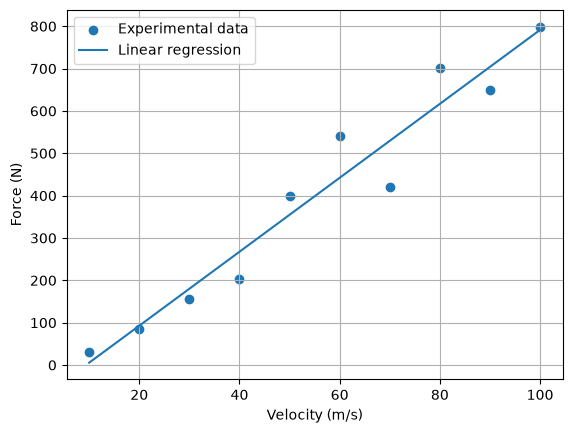

In [21]:
def LinearRegression(x, y):

    x_mean = np.mean(x)
    y_mean = np.mean(y)

    denominator = np.sum((x - x_mean) ** 2)

    if denominator == 0:
        raise ValueError("Cannot fit a line when all x values are equal")

    a1 = np.sum((x - x_mean) * (y - y_mean)) / denominator
    a0 = y_mean - a1 * x_mean

    X = sp.Symbol('x', real=True)
    simbolic = sp.Float(a0) + sp.Float(a1) * X

    f = sp.lambdify(X, simbolic, modules="numpy")

    return simbolic, f

v = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=float)
F = np.array([30, 84, 155, 204, 400, 540, 421, 702, 650, 799], dtype=float)

f_linear_sym, f_linear = LinearRegression(v, F)

print(f"Linear model: {f_linear_sym}")


print("\nLinear prediction:", f_linear(30))

v_plot = np.linspace(v.min(), v.max(), 300)

plt.scatter(v, F, label="Experimental data")
plt.plot(v_plot, f_linear(v_plot), label="Linear regression")


plt.xlabel("Velocity (m/s)")
plt.ylabel("Force (N)")
plt.legend()
plt.grid(True)
plt.show()

# Power Regression

Power model: 1.1359181761878*x**1.44135063800283

Power prediction: 152.89620702592322


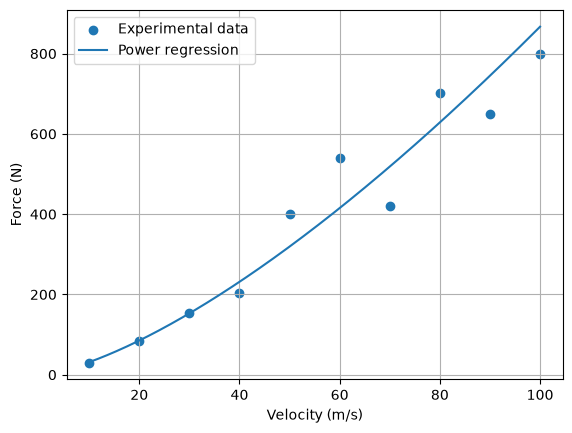

In [22]:

def PowerRegression(x, y):
    if np.any(x <= 0) or np.any(y <= 0):
        raise ValueError("Power regression requires positive x and y")

    log_x = np.log(x)
    log_y = np.log(y)

    A, f_log_lambda = LinearRegression(log_x, log_y)

    log_X = sp.Symbol('x', real=True)
    A0 = float(A.subs(log_X, 0))
    beta = float(A.coeff(log_X))

    alpha = np.exp(A0)

    X = sp.Symbol('x', positive=True)
    f_sym = sp.Float(alpha) * X ** sp.Float(beta)

    f_lambda = sp.lambdify(X, f_sym, modules="numpy")

    return f_sym, f_lambda


v = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=float)
F = np.array([30, 84, 155, 204, 400, 540, 421, 702, 650, 799], dtype=float)

f_Power_sym, f_Power = PowerRegression(v, F)

print(f"Power model: {f_Power_sym}")


print("\nPower prediction:", f_Power(30))

v_plot = np.linspace(v.min(), v.max(), 300)

plt.scatter(v, F, label="Experimental data")
plt.plot(v_plot, f_Power(v_plot), label="Power regression")


plt.xlabel("Velocity (m/s)")
plt.ylabel("Force (N)")
plt.legend()
plt.grid(True)
plt.show()

# Cubic Natural Spline

[0, 10]  a=30.00  b=0.2518  c=0.00000  d=-0.003518
[10, 20]  a=29.00  b=-0.8036  c=-0.10554  d=0.004590
[20, 30]  a=15.00  b=-1.5374  c=0.03215  d=0.001159
[30, 40]  a=4.00  b=-0.5467  c=0.06692  d=0.000774
[40, 50]  a=6.00  b=1.0241  c=0.09015  d=-0.005256
[50, 60]  a=20.00  b=1.2503  c=-0.06754  d=0.002251
h(5 m) = 30.819 m
h(25 m) = 8.262 m
h(35 m) = 3.037 m
h(55 m) = 24.844 m


AttributeError: module 'matplotlib.pyplot' has no attribute 'set_ylabel'

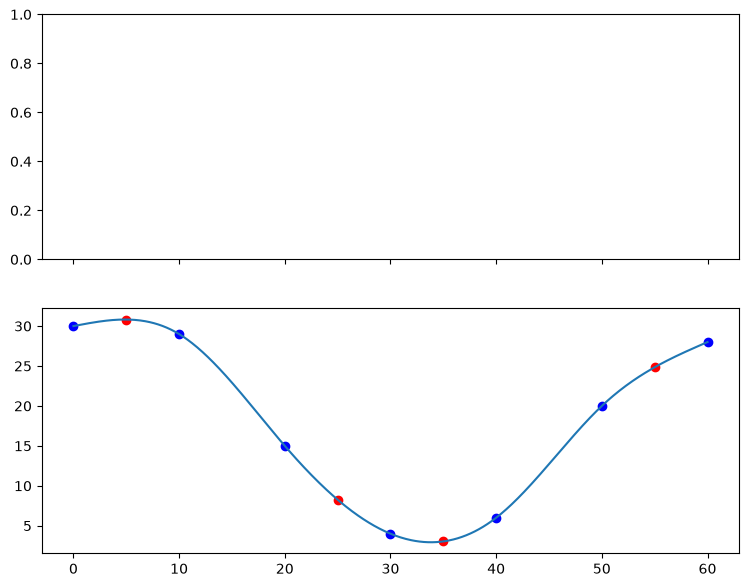

In [ ]:
def NaturalSpline( x_pts: np.array , y_pts: np.array ):
    intervals = len(x_pts) - 1
    intervalsWidths = np.diff(x_pts)

    lower = np.zeros(intervals - 1)
    diag = np.zeros(intervals - 1)
    upper = np.zeros(intervals - 1)
    rhs = np.zeros(intervals - 1)

    for i in range(1, intervals):
        k = i - 1
        lower[k] = intervalsWidths[i - 1]
        diag[k] = 2 * (intervalsWidths[i - 1] + intervalsWidths[i])
        upper[k] = intervalsWidths[i]
        rhs[k] = 3 * ((y_pts[i + 1] - y_pts[i]) / intervalsWidths[i] - (y_pts[i] - y_pts[i - 1]) / intervalsWidths[i - 1])

    c = np.zeros(intervals + 1)           
    c[1:intervals] = SolveTridiagonal(lower, diag, upper, rhs)

    a = y_pts[:-1].copy()
    b = (y_pts[1:] - y_pts[:-1]) / intervalsWidths - intervalsWidths * (2 * c[:-1] + c[1:]) / 3
    d = (c[1:] - c[:-1]) / (3 * intervalsWidths)

    return a, b, c[:-1], d

def SolveTridiagonal(lower, diag, upper, rhs):
    m = len(rhs)
    diag = diag.copy()
    rhs = rhs.copy()

    for i in range(1, m):
        factor = lower[i] / diag[i - 1]
        diag[i] -= factor * upper[i - 1]
        rhs[i] -= factor * rhs[i - 1]

    sol = np.zeros(m)
    sol[-1] = rhs[-1] / diag[-1]
    for i in range(m - 2, -1, -1):
        sol[i] = (rhs[i] - upper[i] * sol[i + 1]) / diag[i]

    return sol

def EvaluateSpline(xu, x, a, b, c, d):
    for i in range(len(x) - 1):
        if x[i] <= xu <= x[i + 1]:
            dx = xu - x[i]
            return a[i] + b[i] * dx + c[i] * dx**2 + d[i] * dx**3
    raise ValueError("xu is outside the interval")
